# Sales Forecasting for a Retail Store (Walmart)

**Goal:** Analyze historical weekly sales of 45 Walmart stores, find useful business insights, and forecast future sales using time-series models.

**Models compared:** ARIMA, SARIMA, Holt-Winters, and Prophet

**Metrics used:** MAE, RMSE, and MAPE

## Step 1: Import Libraries

In [1]:
import warnings
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet').disabled = True
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

## Step 2: Load the Data

In [2]:
df = pd.read_csv('Walmart.csv')
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [3]:
print('Rows and columns:', df.shape)
df.info()

Rows and columns: (6435, 8)
<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   str    
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), str(1)
memory usage: 402.3 KB


## Step 3: Data Cleaning

In [4]:
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

print('Missing values:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())

Missing values:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Duplicate rows: 0


In [5]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)

print('Number of stores:', df['Store'].nunique())
print('Date range:', df['Date'].min().date(), 'to', df['Date'].max().date())
print('Number of weeks:', df['Date'].nunique())
df.describe().round(2)

Number of stores: 45
Date range: 2010-02-05 to 2012-10-26
Number of weeks: 143


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Week
count,6435.00,6435,6435.00,6435.00,6435.00,6435.00,6435.00,6435.00,6435.00,6435.00,6435.00
mean,23.00,2011-06-17 00:00:00,1046964.88,0.07,60.66,3.36,171.58,8.00,2010.97,6.45,25.82
min,1.00,2010-02-05 00:00:00,209986.25,0.00,-2.06,2.47,126.06,3.88,2010.00,1.00,1.00
25%,12.00,2010-10-08 00:00:00,553350.10,0.00,47.46,2.93,131.74,6.89,2010.00,4.00,14.00
50%,23.00,2011-06-17 00:00:00,960746.04,0.00,62.67,3.44,182.62,7.87,2011.00,6.00,26.00
75%,34.00,2012-02-24 00:00:00,1420158.66,0.00,74.94,3.74,212.74,8.62,2012.00,9.00,38.00
max,45.00,2012-10-26 00:00:00,3818686.45,1.00,100.14,4.47,227.23,14.31,2012.00,12.00,52.00
std,12.99,NaN,564366.62,0.26,18.44,0.46,39.36,1.88,0.80,3.24,14.13


## Step 4: Exploratory Data Analysis

### 4.1 Total Weekly Sales Over Time

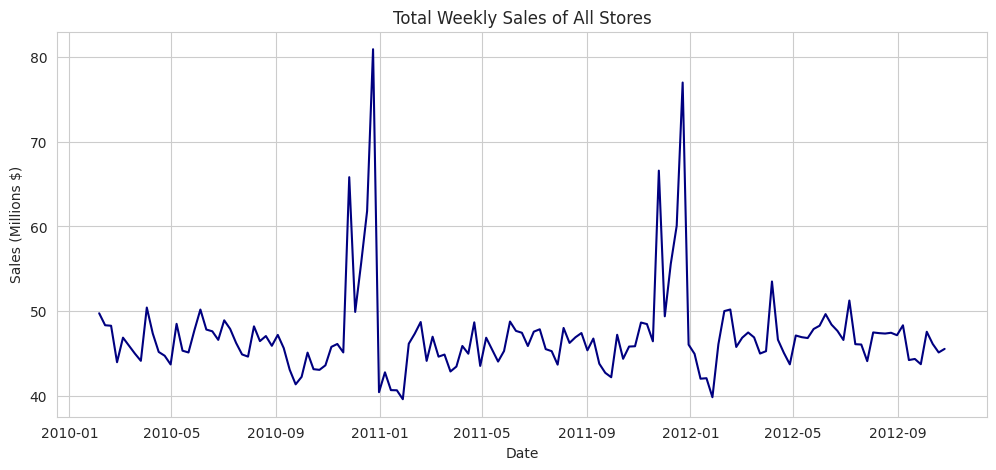

In [6]:
total_sales = df.groupby('Date')['Weekly_Sales'].sum()

plt.plot(total_sales.index, total_sales.values / 1e6, color='navy')
plt.title('Total Weekly Sales of All Stores')
plt.xlabel('Date')
plt.ylabel('Sales (Millions $)')
plt.show()

### 4.2 Average Weekly Sales by Store

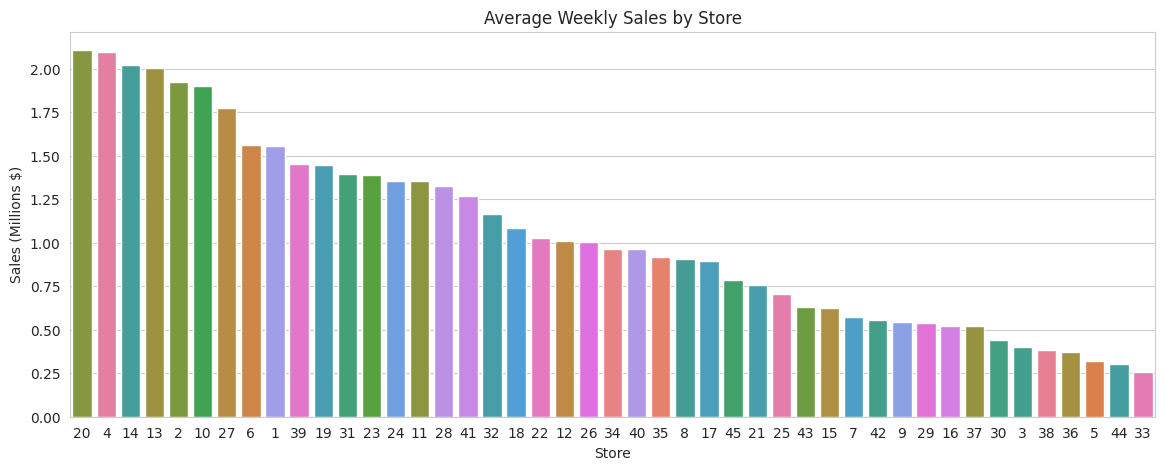

Top 3 stores:
Store
20    2107677.0
4     2094713.0
14    2020978.0
Name: Weekly_Sales, dtype: float64

Bottom 3 stores:
Store
5     318012.0
44    302749.0
33    259862.0
Name: Weekly_Sales, dtype: float64


In [7]:
store_avg = df.groupby('Store')['Weekly_Sales'].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 5))
store_names = store_avg.index.astype(str)
colors = sns.color_palette('husl', len(store_avg))
np.random.seed(3)
np.random.shuffle(colors)
sns.barplot(x=store_names, y=store_avg.values / 1e6, hue=store_names, palette=colors, legend=False)
plt.title('Average Weekly Sales by Store')
plt.xlabel('Store')
plt.ylabel('Sales (Millions $)')
plt.show()

print('Top 3 stores:')
print(store_avg.head(3).round(0))
print()
print('Bottom 3 stores:')
print(store_avg.tail(3).round(0))

### 4.3 Holiday vs Non-Holiday Sales

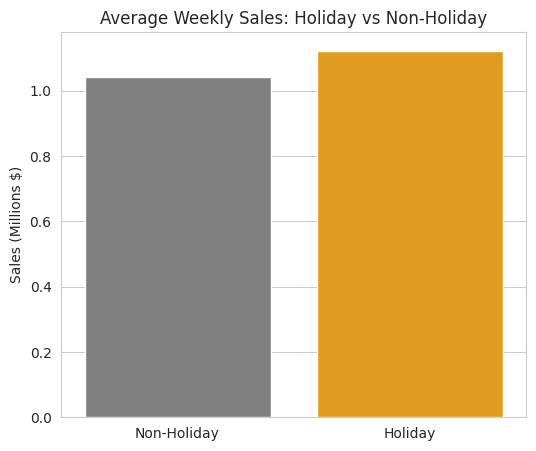

Holiday_Flag
0    1041256.0
1    1122888.0
Name: Weekly_Sales, dtype: float64


In [8]:
holiday_avg = df.groupby('Holiday_Flag')['Weekly_Sales'].mean()

plt.figure(figsize=(6, 5))
sns.barplot(x=['Non-Holiday', 'Holiday'], y=holiday_avg.values / 1e6, palette=['gray', 'orange'])
plt.title('Average Weekly Sales: Holiday vs Non-Holiday')
plt.ylabel('Sales (Millions $)')
plt.show()

print(holiday_avg.round(0))

### 4.4 Sales on Each Holiday Week

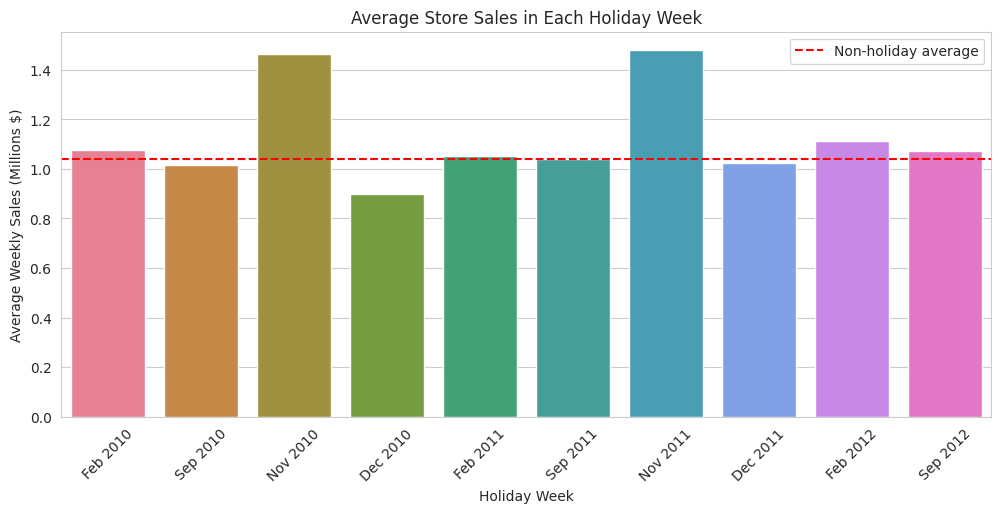

In [9]:
holiday_weeks = df[df['Holiday_Flag'] == 1].groupby('Date')['Weekly_Sales'].mean().reset_index()
holiday_weeks['Label'] = holiday_weeks['Date'].dt.strftime('%b %Y')
holiday_weeks['Sales_M'] = holiday_weeks['Weekly_Sales'] / 1e6
normal_avg = df[df['Holiday_Flag'] == 0]['Weekly_Sales'].mean() / 1e6

plt.figure(figsize=(12, 5))
colors = sns.color_palette('husl', len(holiday_weeks))
sns.barplot(data=holiday_weeks, x='Label', y='Sales_M', hue='Label', palette=colors, legend=False)
plt.axhline(normal_avg, color='red', linestyle='--', label='Non-holiday average')
plt.title('Average Store Sales in Each Holiday Week')
plt.xlabel('Holiday Week')
plt.ylabel('Average Weekly Sales (Millions $)')
plt.xticks(rotation=45)
plt.legend()
plt.show()

### 4.5 Monthly Sales Pattern

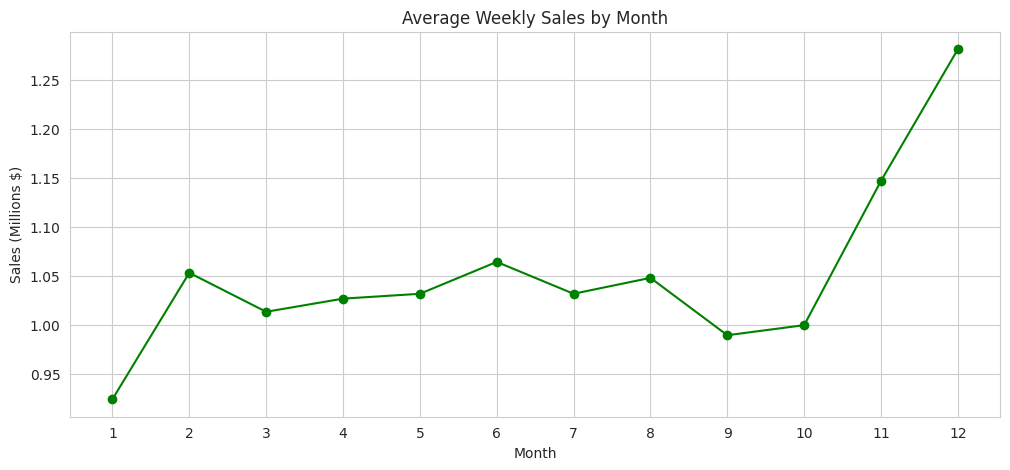

In [10]:
month_avg = df.groupby('Month')['Weekly_Sales'].mean()

plt.plot(month_avg.index, month_avg.values / 1e6, marker='o', color='green')
plt.title('Average Weekly Sales by Month')
plt.xlabel('Month')
plt.ylabel('Sales (Millions $)')
plt.xticks(range(1, 13))
plt.show()

### 4.6 Yearly Comparison

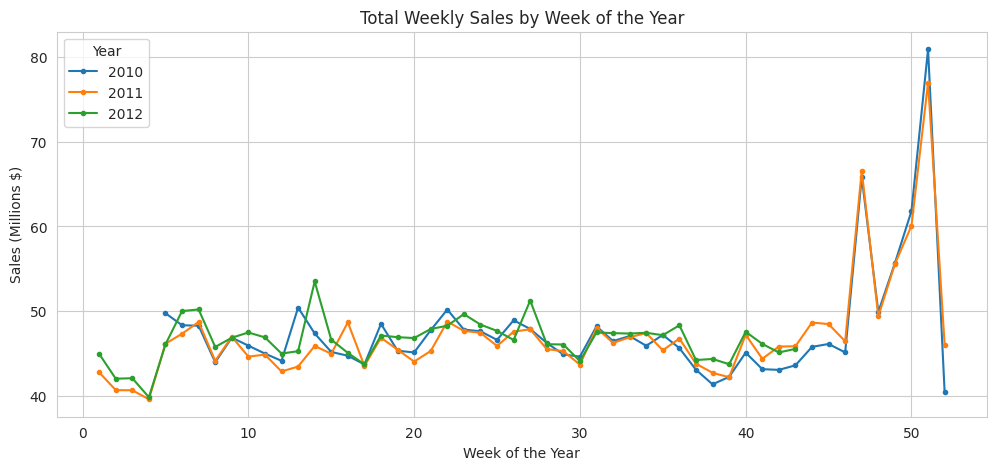

In [11]:
yearly = df.groupby(['Year', 'Week'])['Weekly_Sales'].sum().unstack(0) / 1e6

yearly.plot(marker='.')
plt.title('Total Weekly Sales by Week of the Year')
plt.xlabel('Week of the Year')
plt.ylabel('Sales (Millions $)')
plt.legend(title='Year')
plt.show()

### 4.7 Effect of Temperature, Fuel Price, CPI and Unemployment

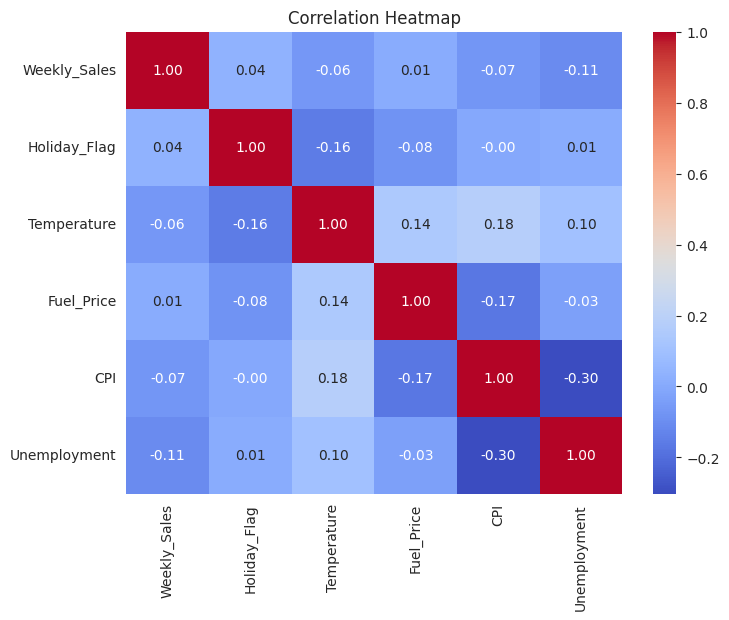

In [12]:
cols = ['Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### 4.8 Top 5 Best Sales Weeks

In [13]:
total_sales.sort_values(ascending=False).head(5).round(0)

Date
2010-12-24    80931416.0
2011-12-23    76998241.0
2011-11-25    66593605.0
2010-11-26    65821003.0
2010-12-17    61820800.0
Name: Weekly_Sales, dtype: float64

## Step 5: Key Insights from the Data

1. **Strong seasonality:** December has the highest average weekly sales (about $1.28M per store) and January the lowest (about $0.92M), which is roughly 39% higher in December. November is also strong.
2. **Biggest sales weeks:** The week just before Christmas is the single best week each year (about $81M in 2010 and $77M in 2011 across all stores), followed by Thanksgiving week.
3. **Holiday flag is misleading for Christmas:** Holiday weeks average about 8% more than normal weeks, but this comes almost entirely from Thanksgiving, where sales are roughly 40% above normal. The flagged Christmas week (ending Dec 31) is actually weak, while the real peak is the unflagged week before Christmas. Super Bowl and Labor Day weeks are close to normal.
4. **Huge gap between stores:** The best store (Store 20) sells about 8 times more per week than the weakest (Store 33). Stores 20, 4 and 14 lead, while Stores 33, 44 and 5 are at the bottom.
5. **Economic factors matter little:** Temperature, fuel price, CPI and unemployment all have very weak correlation with sales (between -0.11 and 0.01). Sales are driven mainly by which store it is and the time of the year.
6. **Data note:** The data ends in October 2012, so 2012 has only 43 weeks and looks lower than other years in total.

## Step 6: Prepare Data for Forecasting

We forecast the **total weekly sales of all stores**. The last 20 weeks are kept as a test set to check how accurate each model is.

In [14]:
series = total_sales.asfreq('W-FRI')
print('Missing weeks:', series.isnull().sum())

test_size = 20
train = series[:-test_size]
test = series[-test_size:]

print('Training weeks:', len(train))
print('Testing weeks:', len(test))

Missing weeks: 0
Training weeks: 123
Testing weeks: 20


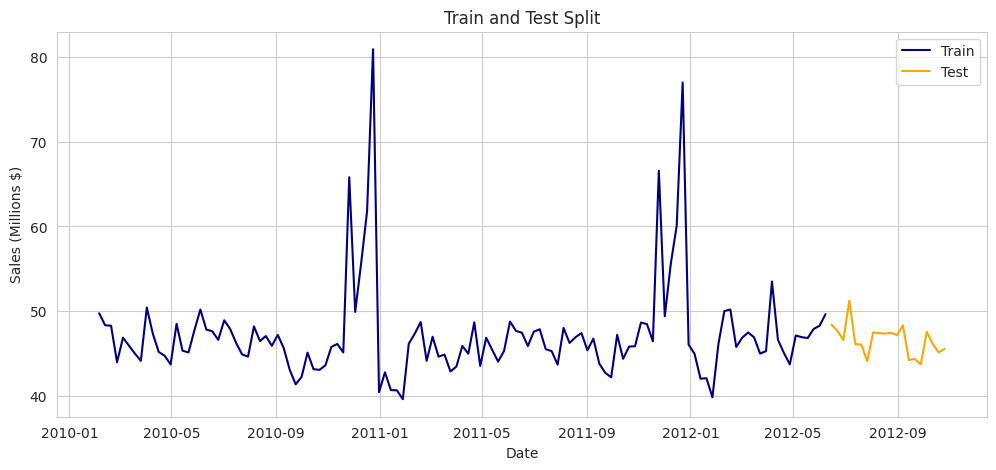

In [15]:
plt.plot(train.index, train.values / 1e6, label='Train', color='navy')
plt.plot(test.index, test.values / 1e6, label='Test', color='orange')
plt.title('Train and Test Split')
plt.xlabel('Date')
plt.ylabel('Sales (Millions $)')
plt.legend()
plt.show()

## Step 7: Build the Forecasting Models

In [16]:
def arima_forecast(data, steps):
    model = ARIMA(data, order=(2, 1, 2)).fit()
    return model.forecast(steps).values


def sarima_forecast(data, steps):
    model = SARIMAX(data, order=(1, 1, 1), seasonal_order=(1, 1, 0, 52),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return model.forecast(steps).values


def holt_winters_forecast(data, steps):
    model = ExponentialSmoothing(data, trend='add', seasonal='add', seasonal_periods=52).fit()
    return model.forecast(steps).values


def prophet_forecast(data, steps):
    frame = data.reset_index()
    frame.columns = ['ds', 'y']
    model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    model.fit(frame)
    future = model.make_future_dataframe(periods=steps, freq='W-FRI')
    return model.predict(future)['yhat'].values[-steps:]


def get_scores(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    return mae, rmse, mape

## Step 8: Train, Test and Compare the Models

In [17]:
models = {
    'ARIMA': arima_forecast,
    'SARIMA': sarima_forecast,
    'Holt-Winters': holt_winters_forecast,
    'Prophet': prophet_forecast
}

predictions = {}
scores = []

for name, model_function in models.items():
    predicted = model_function(train, test_size)
    predictions[name] = predicted
    mae, rmse, mape = get_scores(test.values, predicted)
    scores.append([name, mae, rmse, mape])

results = pd.DataFrame(scores, columns=['Model', 'MAE', 'RMSE', 'MAPE (%)']).set_index('Model')
results = results.sort_values('MAPE (%)')
results.round(2)

,MAE,RMSE,MAPE (%)
Model,,,
Holt-Winters,1001996.47,1222769.62,2.14
SARIMA,1006703.20,1268744.01,2.16
Prophet,1058311.06,1447258.46,2.24
ARIMA,1473057.81,1970558.93,3.22


### 8.1 Actual vs Predicted Sales

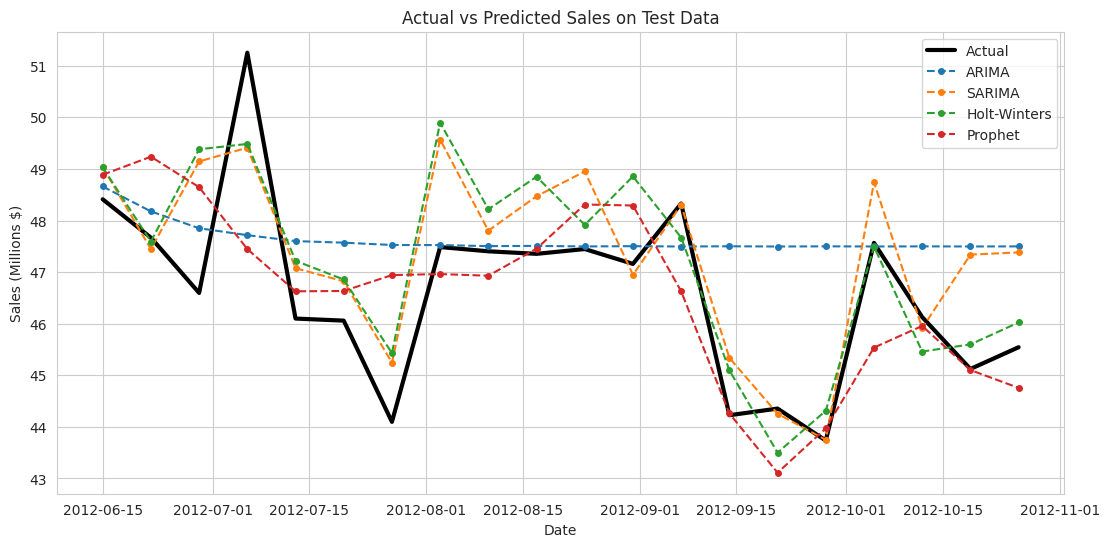

In [18]:
plt.figure(figsize=(13, 6))
plt.plot(test.index, test.values / 1e6, label='Actual', color='black', linewidth=3)

for name, predicted in predictions.items():
    plt.plot(test.index, predicted / 1e6, label=name, linestyle='--', marker='o', markersize=4)

plt.title('Actual vs Predicted Sales on Test Data')
plt.xlabel('Date')
plt.ylabel('Sales (Millions $)')
plt.legend()
plt.show()

### 8.2 Model Comparison

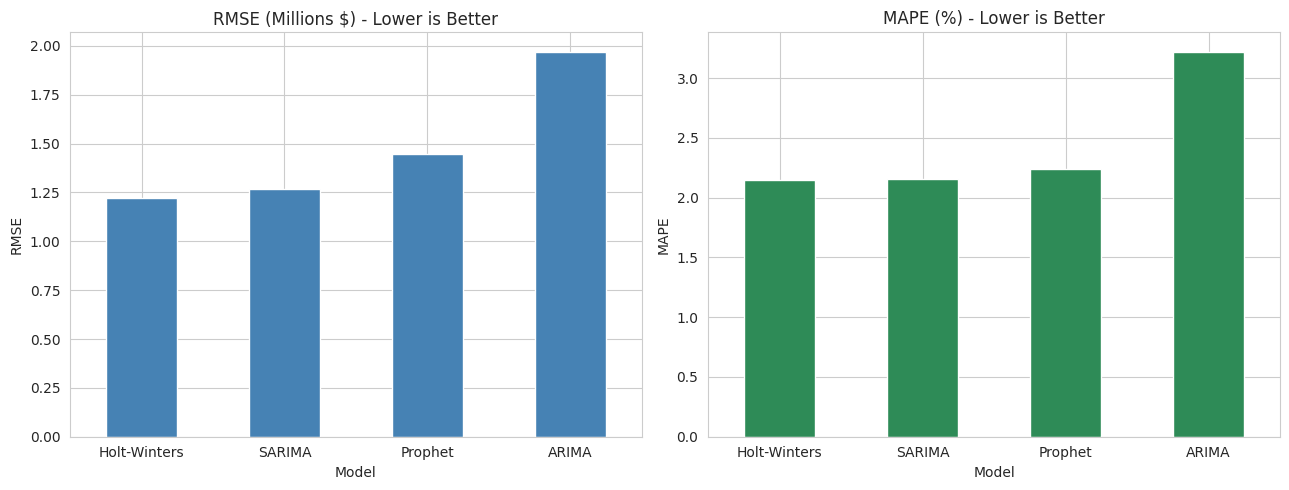

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

results['RMSE'].div(1e6).plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('RMSE (Millions $) - Lower is Better')
axes[0].set_ylabel('RMSE')
axes[0].tick_params(axis='x', rotation=0)

results['MAPE (%)'].plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('MAPE (%) - Lower is Better')
axes[1].set_ylabel('MAPE')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [20]:
best_model = results['MAPE (%)'].idxmin()
print('Best model:', best_model)

Best model: Holt-Winters


## Step 9: Forecast the Next 12 Weeks with the Best Model

In [21]:
future_steps = 12
future_forecast = models[best_model](series, future_steps)
future_dates = pd.date_range(series.index[-1] + pd.Timedelta(weeks=1), periods=future_steps, freq='W-FRI')

forecast_table = pd.DataFrame({'Date': future_dates, 'Forecasted Sales': future_forecast.round(0)})
forecast_table

,Date,Forecasted Sales
0,2012-11-02,47801326.0
1,2012-11-09,48064599.0
2,2012-11-16,46907493.0
3,2012-11-23,67554805.0
4,2012-11-30,51484032.0
5,2012-12-07,57355741.0
6,2012-12-14,63282971.0
7,2012-12-21,82097849.0
8,2012-12-28,43215588.0
9,2013-01-04,44980968.0


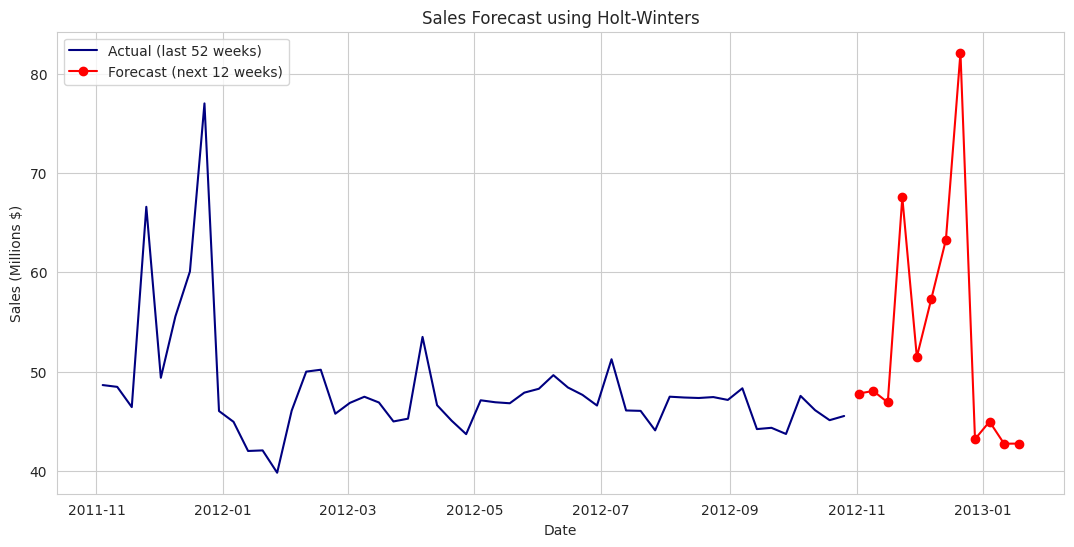

In [22]:
recent = series[-52:]

plt.figure(figsize=(13, 6))
plt.plot(recent.index, recent.values / 1e6, label='Actual (last 52 weeks)', color='navy')
plt.plot(future_dates, future_forecast / 1e6, label='Forecast (next 12 weeks)', color='red', marker='o')
plt.title('Sales Forecast using ' + best_model)
plt.xlabel('Date')
plt.ylabel('Sales (Millions $)')
plt.legend()
plt.show()

## Step 10: Conclusion

**Model results**

- **Holt-Winters** was the most accurate model (MAPE about 2.1%, RMSE about $1.22M), with **SARIMA** almost the same (2.16%) and **Prophet** close behind (2.24%).
- **ARIMA** was the weakest (MAPE about 3.2%) because it has no seasonal component, so it predicts an almost flat line and misses the yearly sales pattern.
- All three seasonal models predict total sales within about 2% on average, which is accurate enough for planning.

**Forecast for the next 12 weeks**

- Sales stay near $47M to $48M per week in early November.
- Thanksgiving week (ending Nov 23, 2012) jumps to about $67.6M.
- The week before Christmas (ending Dec 21, 2012) is the peak at about $82M.
- January falls back to about $43M to $45M per week.

**Business recommendations**

1. Build inventory and staffing before Thanksgiving week and especially the week before Christmas, which is the busiest week of the year.
2. Plan for a slow January by reducing stock orders and shifting staff hours.
3. Do not rely only on the Holiday_Flag column for planning, since it misses the real Christmas peak.
4. Review the weakest stores (33, 44 and 5) and learn from the strongest ones (20, 4 and 14).

**Possible next steps**

- Forecast each store separately instead of the total.
- Add holiday dates as extra inputs to Prophet to improve accuracy.
- Try an LSTM neural network as an advanced model and compare it with these results.